# Drills the Stopwatch Can't See
### Do position-specific Combine drills (pass rush, pass-pro mirror, route running) translate to NFL production?
**NFL Big Data Bowl 2027** | Notebook companion to the Writeup

**Why this notebook.** A first test (40-yard dash and cone/shuttle tracking) found that whole-run features were redundant with the stopwatch (fitted top speed is ~92% explained by forty time + weight) and added no out-of-fold forecast skill. Those drills have stopwatch equivalents. **Position drills do not**: ~390k of the 463k Combine tracking rows are pass-rush, mirror, route, back-pedal and wave drills that exist *only* in tracking. That is where tracking can be new information.

**Hypotheses fixed before looking at results** (primary = counted in the headline; secondary = exploratory)
| ID | Position | Combine drill(s) | NFL outcome (context-adjusted) | Why it should link |
|---|---|---|---|---|
| H1 (primary) | EDGE/DL | `PASS_RUSH_DRILL` | **Get-off speed** (`player_get_off`, higher = faster) | same skill: first step across a line, now measured per snap in games |
| H2 (primary) | OL | `PASS_PRO-MIRROR_DRILL` | **Pressure allowed** per pass-block snap | mirroring a rusher laterally is the pass-pro skill |
| H3 (primary) | WR/TE | all route drills, pooled | **Separation at pass_forward** | speed retained through breaks should show up as separation |
| S1 | EDGE/DL | `PASS_RUSH_DRILL` | pressure generated | |
| S2 | OL | `PASS_RUSH_DROP` + `FIVE_YARD_WAVE...` | pressure allowed | |
| S3 | EDGE/DL | pass-rush + hoop + front-start wave | get-off speed | |

**Test**: nested out-of-fold models. `A` draft capital + size, `B` = A + stopwatch/NGS athleticism, `C` = B + drill features. Statistic ΔR² = R²(C) − R²(B) with paired-bootstrap CI, permutation test, Benjamini–Hochberg correction across all six, and a 2025-class temporal holdout.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV, Ridge, LogisticRegression
from sklearn.model_selection import RepeatedKFold

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})

def find_data():
    env = os.environ.get("BDB_DATA")
    if env: return env
    hits = glob.glob("/kaggle/input/**/players.csv", recursive=True)
    if hits: return os.path.dirname(hits[0])
    raise FileNotFoundError("Set BDB_DATA to the folder containing players.csv")

DATA = find_data()
FAST = os.environ.get("BDB_FAST", "0") == "1"
N_PERM, N_BOOT, N_REP = (20, 100, 3) if FAST else (200, 1000, 10)

players = pd.read_csv(f"{DATA}/players.csv")
comb    = pd.read_csv(f"{DATA}/combine_results.csv")
ctrk    = pd.read_csv(f"{DATA}/combine_tracking.csv")
games   = pd.read_csv(f"{DATA}/games.csv")
pp      = pd.read_csv(f"{DATA}/player_play.csv", usecols=lambda c: c != "play_description")

POS_GROUP = {"DE": "EDGE_DL", "OLB": "EDGE_DL", "DT": "EDGE_DL", "NT": "EDGE_DL",
             "T": "OL", "G": "OL", "C": "OL", "WR": "WR_TE", "TE": "WR_TE",
             "CB": "DB", "SS": "DB", "FS": "DB", "DB": "DB", "RB": "RB", "FB": "RB", "ILB": "LB", "MLB": "LB"}
players["birth_date"] = pd.to_datetime(players["birth_date"])
base = players.merge(comb.drop(columns=["draft_year"], errors="ignore"), on="nfl_id", how="left")
base["pos_group"] = base["nfl_position"].map(POS_GROUP)
base["age_at_draft"] = (pd.to_datetime(base["draft_year"].astype(str) + "-04-25") - base["birth_date"]).dt.days / 365.25
base["pick"] = base["draft_overall_pick"].fillna(260); base["log_pick"] = np.log(base["pick"])
base = base[base["pos_group"].notna()].copy()
print(base["pos_group"].value_counts().to_dict())

{'WR_TE': 148, 'OL': 121, 'EDGE_DL': 118, 'DB': 118, 'LB': 3, 'RB': 2}


## 1. A generic movement signature for any drill track
For each drill attempt (start = first frame above 1 yd/s, end = last): duration, path length, top/mean speed, **peak acceleration and deceleration**, **first-step** features (distance and speed at 1 s), path efficiency, **turning** (rate, speed kept through the sharpest turns) and a **break** (the sharpest 0.5 s heading change: speed in vs speed at the break, exit speed, braking and re-acceleration).
Everything comes from x, y, s, a, dir, so the same function works for pass-rush, mirror and route drills. Features are averaged over a player's attempts.

In [2]:
def _sec(g):
    tm = pd.to_datetime(g["time"]); return (tm - tm.iloc[0]).dt.total_seconds().values

FEATS = ["dur", "path", "smax", "smean", "a_p98", "a_p02", "d_1s", "s_at_1s", "path_eff",
         "turn_rate_p95", "turn_speed_ratio", "total_turn", "cut_angle", "cut_speed_ratio", "cut_exit_ratio", "cut_decel", "cut_reaccel"]

def move_features(g):
    g = g.sort_values("time")
    if len(g) < 15: return None
    t = _sec(g); s = g["s"].values.astype(float); a = g["a"].values.astype(float)
    x = g["x"].values.astype(float); y = g["y"].values.astype(float); dr = g["dir"].values.astype(float)
    s = pd.Series(s).interpolate(limit_direction="both").values; a = pd.Series(a).interpolate(limit_direction="both").values
    if np.isnan(s).any(): return None
    mv = np.where(s > 1.0)[0]
    if len(mv) < 10: return None
    i0, i1 = max(mv[0] - 1, 0), mv[-1]
    t, s, a, x, y, dr = [v[i0:i1 + 1] for v in (t, s, a, x, y, dr)]
    t = t - t[0]
    if len(t) < 10 or np.isnan(s).any(): return None
    cum = np.r_[0.0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    f = dict(dur=t[-1], path=cum[-1], smax=s.max(), smean=s.mean(),
             a_p98=np.nanpercentile(a, 98), a_p02=np.nanpercentile(a, 2),
             path_eff=np.hypot(x[-1] - x[0], y[-1] - y[0]) / max(cum[-1], 1e-6))
    f["d_1s"] = float(np.interp(1.0, t, cum)) if t[-1] >= 1.0 else np.nan
    f["s_at_1s"] = float(np.interp(1.0, t, s)) if t[-1] >= 1.0 else np.nan
    dr = pd.Series(dr).ffill().bfill().values
    if np.isnan(dr).any(): return f
    unw = np.unwrap(np.radians(dr))
    dth = np.degrees(np.abs(np.diff(unw))) / 0.1
    m = s[1:] > 2.0
    if m.sum() >= 5:
        f["total_turn"] = float(np.degrees(np.abs(np.diff(unw)))[m].sum())
        f["turn_rate_p95"] = float(np.percentile(dth[m], 95))
        top = m & (dth >= np.percentile(dth[m], 90))
        f["turn_speed_ratio"] = float(s[1:][top].mean() / s.max()) if top.sum() else np.nan
    w = 5
    if len(unw) > 2 * w + 2:
        ang = np.abs(unw[w:] - unw[:-w]); k = int(np.argmax(ang)); c = k + w // 2
        if np.degrees(ang[k]) >= 30 and c >= 3:
            pre = s[max(0, c - 10):c].max()
            if pre > 0:
                f.update(cut_angle=float(np.degrees(ang[k])), cut_speed_ratio=float(s[max(0, c - 3):c + 4].min() / pre),
                         cut_exit_ratio=float(s[c:c + 11].max() / pre), cut_decel=float(np.nanmin(a[max(0, c - 10):c + 1])),
                         cut_reaccel=float(np.nanmax(a[c:c + 11])))
    return f

ROUTES = sorted(ctrk.loc[ctrk.drill_type.isin(["SKILL_DRILLS_WR", "SKILL_DRILLS_TE"]) &
                         ctrk.drill_name.str.contains("ROUTE", na=False), "drill_name"].unique())
DRILL_SETS = {"rush": ["PASS_RUSH_DRILL"], "hoop": ["RUN_THE_HOOP_DRILL"],
              "fsw": ["FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION"],
              "mirror": ["PASS_PRO-MIRROR_DRILL"], "drop": ["PASS_RUSH_DROP"],
              "wave": ["FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE"], "routes": ROUTES}
DRILL2SET = {dn: k for k, v in DRILL_SETS.items() for dn in v}
print("route drills pooled:", len(ROUTES))

d = ctrk[(ctrk.entity_type == "PLAYER") & ctrk.nfl_id.notna() & ctrk.drill_name.isin(DRILL2SET)]
rows = []
for (nid, dn, eid, att), g in d.groupby(["nfl_id", "drill_name", "event_id", "attempt"]):
    f = move_features(g)
    if f: f.update(nfl_id=int(nid), drill_name=dn, set=DRILL2SET[dn], attempt=att); rows.append(f)
att_df = pd.DataFrame(rows)
print("attempts with features:", len(att_df)); display(att_df.groupby("set").agg(attempts=("nfl_id", "size"), players=("nfl_id", "nunique")))

dw = att_df.groupby(["nfl_id", "set"])[FEATS].mean().unstack("set")
dw.columns = [f"{s}__{f}" for f, s in dw.columns]; dw = dw.reset_index()
feat = base.merge(dw, on="nfl_id", how="left")

route drills pooled: 16
attempts with features: 2214


,attempts,players
set,,
drop,239,120
fsw,112,112
hoop,119,109
mirror,84,84
routes,1315,149
rush,225,118
wave,120,120


### Are the drill features measured reliably?
Split-half reliability (random halves of a player's attempts, Spearman–Brown) per feature, for players with ≥2 attempts. A feature that is not stable inside one Combine cannot predict anything in the NFL.

In [3]:
def sh_rel(set_name):
    """Odd/even-attempt split-half reliability (Spearman-Brown). NaN where players have only one attempt."""
    a = att_df[att_df.set == set_name].sort_values(["nfl_id", "drill_name", "attempt"]).copy()
    n = a.groupby("nfl_id").size(); a = a[a.nfl_id.isin(n[n >= 2].index)]
    out = {c: np.nan for c in FEATS}
    if a.empty: return pd.Series(out)
    a["h"] = a.groupby("nfl_id").cumcount() % 2
    m = a.groupby(["nfl_id", "h"])[FEATS].mean().unstack("h")
    for c in FEATS:
        if c in m.columns.get_level_values(0) and {0, 1} <= set(m[c].columns):
            z = m[c].dropna()
            if len(z) >= 15:
                rr = z[0].corr(z[1]); out[c] = 2 * rr / (1 + rr)
    return pd.Series(out)
rel_drill = pd.DataFrame({k: sh_rel(k) for k in DRILL_SETS}).round(2)
print("(NaN = players have a single attempt in that drill, so split-half is not estimable)")
display(rel_drill)

(NaN = players have a single attempt in that drill, so split-half is not estimable)


,rush,hoop,fsw,mirror,drop,wave,routes
dur,0.19,NaN,NaN,NaN,-0.09,NaN,-0.63
path,0.51,NaN,NaN,NaN,0.02,NaN,-1.83
smax,0.78,NaN,NaN,NaN,0.75,NaN,0.21
smean,0.45,NaN,NaN,NaN,0.04,NaN,-0.53
a_p98,0.61,NaN,NaN,NaN,0.45,NaN,0.69
a_p02,0.59,NaN,NaN,NaN,-0.15,NaN,0.22
d_1s,0.58,NaN,NaN,NaN,-0.03,NaN,0.69
s_at_1s,0.69,NaN,NaN,NaN,-0.05,NaN,0.57
path_eff,0.44,NaN,NaN,NaN,0.19,NaN,0.46
turn_rate_p95,0.48,NaN,NaN,NaN,0.27,NaN,-0.24


## 2. NFL outcomes, adjusted for football context
Same method as before: fit a context model on all rookie snaps, take each player's residual, shrink by snap count (empirical Bayes). New outcome: **get-off speed** = −`player_get_off` (seconds from snap until the rusher crosses the line of scrimmage), adjusted for alignment, down/distance, blitz, formation and coverage.

In [4]:
pp = pp.merge(base[["nfl_id", "pos_group"]], on="nfl_id").merge(
    games[["game_id", "season", "season_type", "home_team_abbr", "visitor_team_abbr"]], on="game_id", how="inner")
home_off = pp.possession_team == pp.home_team_abbr
pp["offense_wp"] = np.where(home_off, pp.pre_snap_home_team_win_probability, pp.pre_snap_visitor_team_win_probability)
pp["off_score_diff"] = np.where(home_off, pp.pre_snap_home_score - pp.pre_snap_visitor_score, pp.pre_snap_visitor_score - pp.pre_snap_home_score)

pp["season"] = pp["season"].astype(str)
NUM = ["down", "yards_to_go", "quarter", "yardline_number", "offense_wp", "off_score_diff"]
CAT = ["offense_formation", "receiver_alignment", "team_coverage_man_zone", "team_coverage_type", "lined_up_position"]

def fit_expected(d, y, kind, num, cat):
    num = [c for c in num if c in d]; cat = [c for c in cat if c in d]
    X = d[num + cat].copy()
    for c in cat: X[c] = X[c].fillna("NA").astype(str)
    pre = ColumnTransformer([("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
                             ("c", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat)])
    est = LogisticRegression(C=.3, max_iter=1000) if kind == "bin" else Ridge(alpha=10)
    m = make_pipeline(pre, est).fit(X, y)
    return m.predict_proba(X)[:, 1] if kind == "bin" else m.predict(X)

def eb_shrink(df, col):
    g = df.groupby("nfl_id")[col].agg(["mean", "count"]); s2 = df[col].var()
    t2 = max(g["mean"].var() - (s2 / g["count"]).mean(), 1e-9); k = s2 / t2
    g["y"] = g["mean"] * g["count"] / (g["count"] + k); g["w"] = g["count"] / (g["count"] + k)
    return g.rename(columns={"count": "n"})[["n", "y", "w"]], k

def split_half(df, col, seed=0):
    r = np.random.default_rng(seed); d = df[["nfl_id", col]].copy(); d["h"] = r.integers(0, 2, len(d))
    m = d.groupby(["nfl_id", "h"])[col].mean().unstack().dropna(); rr = m[0].corr(m[1]); return 2 * rr / (1 + rr)

SPECS = {
 "Get-off speed over expected": dict(groups=["EDGE_DL"], kind="cont", min_n=100,
     filt=lambda d: d.player_get_off.notna(), y=lambda d: -d.player_get_off, num=NUM, cat=CAT + ["blitzing"]),
 "Pass-rush pressure over expected": dict(groups=["EDGE_DL"], kind="bin", min_n=100,
     filt=lambda d: d.player_get_off.notna(), y=lambda d: d.time_to_pressure.notna().astype(float), num=NUM, cat=CAT + ["blitzing"]),
 "Pressure allowed over expected (OL)": dict(groups=["OL"], kind="bin", min_n=100,
     filt=lambda d: d.pass_rushers_encountered.notna(), y=lambda d: d.pressure_allowed.astype(float), num=NUM, cat=CAT),
 "Separation over expected": dict(groups=["WR_TE"], kind="cont", min_n=30,
     filt=lambda d: d.separation_at_pass_forward.notna(), y=lambda d: d.separation_at_pass_forward,
     num=NUM + ["cushion"], cat=["route_ran", "team_coverage_man_zone", "team_coverage_type", "offense_formation", "receiver_alignment", "in_motion_at_ball_snap"]),
}
# Robustness: same outcomes, additionally adjusted for team and season (scheme / stance / coaching / QB effects)
for k0 in ["Get-off speed over expected", "Pressure allowed over expected (OL)", "Separation over expected"]:
    sp = dict(SPECS[k0]); sp["cat"] = sp["cat"] + ["team_abbr", "season"]; SPECS[k0 + " [team-adj]"] = sp
targets, reli = {}, {}
for name, sp in SPECS.items():
    d = pp[pp.pos_group.isin(sp["groups"])]; d = d[sp["filt"](d)].copy()
    d["y"] = sp["y"](d).astype(float); d = d[d.y.notna()]
    d["res"] = d.y - fit_expected(d, d.y, sp["kind"], sp["num"], sp["cat"])
    cnt = d.groupby("nfl_id").size(); d = d[d.nfl_id.isin(cnt[cnt >= sp["min_n"]].index)]
    t, k = eb_shrink(d, "res"); reli[name] = split_half(d, "res")
    targets[name] = dict(df=t.reset_index(), groups=sp["groups"])
    print(f"{name}: players={len(t)}, median snaps={int(t.n.median())}, split-half reliability={reli[name]:.2f}")

Get-off speed over expected: players=85, median snaps=335, split-half reliability=0.92
Pass-rush pressure over expected: players=85, median snaps=335, split-half reliability=0.57
Pressure allowed over expected (OL): players=89, median snaps=574, split-half reliability=0.27
Separation over expected: players=129, median snaps=248, split-half reliability=0.51
Get-off speed over expected [team-adj]: players=85, median snaps=335, split-half reliability=0.87
Pressure allowed over expected (OL) [team-adj]: players=89, median snaps=574, split-half reliability=-0.07
Separation over expected [team-adj]: players=129, median snaps=248, split-half reliability=0.41


## 3. Does the drill add signal beyond the stopwatch? Nested out-of-fold models
* **A** log draft pick + height + weight + age   * **B** = A + stopwatch (40, 10-yd, vertical, broad, 3-cone, shuttle, bench, NGS athleticism)
* **C** = B + drill features   * **D** = A + drill features only
Ridge (alpha by LOO-CV inside each training fold), reliability-weighted, 5-fold × repeats; paired bootstrap on out-of-fold predictions; permutation null (drill-feature rows shuffled across players).

In [5]:
CTX = ["log_pick", "combine_height", "combine_weight", "age_at_draft"]
TRAD = ["forty", "ten_yd_split", "vertical", "broad_jump", "three_cone", "short_shuttle", "bench_reps", "ngs_athleticism_score"]
HYP = [("H1", "Get-off speed over expected", ["rush"], True),
       ("H2", "Pressure allowed over expected (OL)", ["mirror"], True),
       ("H3", "Separation over expected", ["routes"], True),
       ("S1", "Pass-rush pressure over expected", ["rush"], False),
       ("S2", "Pressure allowed over expected (OL)", ["drop", "wave"], False),
       ("S3", "Get-off speed over expected", ["rush", "hoop", "fsw"], False),
       ("R1", "Get-off speed over expected [team-adj]", ["rush"], False),
       ("R2", "Pressure allowed over expected (OL) [team-adj]", ["mirror"], False),
       ("R3", "Separation over expected [team-adj]", ["routes"], False)]

def make_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 20)))
def oof(X, y, w, repeats, seed=0):
    acc, cnt = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in RepeatedKFold(n_splits=5, n_repeats=repeats, random_state=seed).split(X):
        m = make_model().fit(X.iloc[tr], y[tr], ridgecv__sample_weight=w[tr]); acc[te] += m.predict(X.iloc[te]); cnt[te] += 1
    return acc / cnt
def r2w(y, p, w):
    yb = np.average(y, weights=w); return 1 - np.sum(w * (y - p) ** 2) / np.sum(w * (y - yb) ** 2)
def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q, 1); return out
def usable(df, cols, thr=.4):
    return [c for c in cols if c in df and df[c].isna().mean() < thr and df[c].nunique() > 3]

res, store = [], {}
for hid, tname, sets_, primary in HYP:
    T = targets[tname]
    df = T["df"].merge(feat, on="nfl_id"); df = df[df.pos_group.isin(T["groups"])].dropna(subset=["y"]).reset_index(drop=True)
    dcols = [c for c in dw.columns if c.split("__")[0] in sets_]
    cA, cT = usable(df, CTX), usable(df, dcols); cB = cA + usable(df, TRAD)
    if len(df) < 40 or len(cT) < 2: print("skip", hid, len(df), len(cT)); continue
    df = df[df[cT].notna().any(axis=1)].reset_index(drop=True)
    y, w = df.y.values.astype(float), df.w.values.astype(float)
    S_ = {"A": cA, "B": cB, "C": cB + cT, "D": cA + cT}
    P = {k: oof(df[v], y, w, N_REP) for k, v in S_.items()}; R = {k: r2w(y, P[k], w) for k in P}
    r = np.random.default_rng(1); bd = []
    for _ in range(N_BOOT):
        i = r.integers(0, len(y), len(y)); bd.append(r2w(y[i], P["C"][i], w[i]) - r2w(y[i], P["B"][i], w[i]))
    rB = r2w(y, oof(df[S_["B"]], y, w, 2, 1), w); obs = r2w(y, oof(df[S_["C"]], y, w, 2, 1), w) - rB; null = []
    for b in range(N_PERM):
        Xp = df[S_["C"]].copy(); Xp[cT] = Xp[cT].sample(frac=1, random_state=b).values
        null.append(r2w(y, oof(Xp, y, w, 2, 1), w) - rB)
    res.append(dict(id=hid, primary=primary, target=tname, drills="+".join(sets_), n=len(df), n_feat=len(cT),
                    R2_A=R["A"], R2_B=R["B"], R2_C=R["C"], R2_D=R["D"], dR2_CvsB=R["C"] - R["B"],
                    lo=np.percentile(bd, 2.5), hi=np.percentile(bd, 97.5), p_perm=(1 + np.sum(np.array(null) >= obs)) / (1 + N_PERM)))
    store[hid] = dict(df=df, P=P, sets=S_, cT=cT, y=y, w=w, tname=tname)
results = pd.DataFrame(res)
results["family"] = np.where(results.primary, "primary", np.where(results.id.str.startswith("R"), "robustness", "secondary"))
results["p_adj_BH"] = np.nan
for fam_mask in [results.family != "robustness", results.family == "robustness"]:
    if fam_mask.sum(): results.loc[fam_mask, "p_adj_BH"] = bh(results.loc[fam_mask, "p_perm"].values)
display(results.round(3))

,id,primary,target,drills,n,n_feat,R2_A,R2_B,R2_C,R2_D,dR2_CvsB,lo,hi,p_perm,family,p_adj_BH
0,H1,True,Get-off speed over expected,rush,85,17,-0.023,0.012,-0.041,-0.080,-0.053,-0.122,-0.001,0.672,primary,0.711
1,H2,True,Pressure allowed over expected (OL),mirror,58,17,-0.114,-0.105,-0.139,-0.161,-0.034,-0.134,0.092,0.542,primary,0.711
2,H3,True,Separation over expected,routes,129,17,0.078,0.046,0.025,0.041,-0.021,-0.071,0.026,0.667,primary,0.711
3,S1,False,Pass-rush pressure over expected,rush,85,17,0.125,0.092,-0.032,-0.068,-0.124,-0.222,0.003,0.711,secondary,0.711
4,S2,False,Pressure allowed over expected (OL),drop+wave,89,34,-0.040,-0.030,-0.045,-0.042,-0.016,-0.026,-0.007,0.537,secondary,0.711
5,S3,False,Get-off speed over expected,rush+hoop+fsw,85,51,-0.023,0.012,-0.028,-0.041,-0.040,-0.088,0.007,0.547,secondary,0.711
6,R1,False,Get-off speed over expected [team-adj],rush,85,17,0.103,0.089,0.090,0.105,0.001,-0.061,0.059,0.368,robustness,0.552
7,R2,False,Pressure allowed over expected (OL) [team-adj],mirror,58,17,-0.028,-0.051,-0.151,-0.149,-0.100,-0.207,0.020,0.726,robustness,0.726
8,R3,False,Separation over expected [team-adj],routes,129,17,0.087,0.076,0.096,0.096,0.019,-0.085,0.094,0.199,robustness,0.552


### Focused tests and statistical power
The 17-feature ridge has little power at n ≈ 60–130. So for each primary hypothesis we also test **one feature chosen in advance** as the most direct analogue of the NFL skill: first-step distance (H1), mean speed through the mirror drill (H2), speed kept out of a break (H3). Statistic: partial correlation with the NFL outcome after removing A (draft capital + size) or B (+ stopwatch), with a bootstrap 95% CI. Then: the smallest correlation each sample could detect at 80% power.

In [6]:
FOCUS = {"H1": "rush__d_1s", "H2": "mirror__smean", "H3": "routes__cut_exit_ratio"}
def _resid(v, X):
    X1 = np.c_[np.ones(len(X)), X]; return v - X1 @ np.linalg.lstsq(X1, v, rcond=None)[0]
rows = []
for h, f in FOCUS.items():
    if h not in store or f not in store[h]["df"]: continue
    S = store[h]; df = S["df"]
    for ctrl in ("A", "B"):
        cols = S["sets"][ctrl]; d = df[[f, "y"] + cols].dropna(subset=[f, "y"])
        Xc = SimpleImputer(strategy="median").fit_transform(d[cols]); Xc = (Xc - Xc.mean(0)) / (Xc.std(0) + 1e-9)
        ry, rf = _resid(d.y.values, Xc), _resid(d[f].values, Xc); r0 = np.corrcoef(ry, rf)[0, 1]
        rg = np.random.default_rng(3); bs = [np.corrcoef(ry[i], rf[i])[0, 1] for i in (rg.integers(0, len(ry), len(ry)) for _ in range(N_BOOT))]
        rows.append(dict(id=h, feature=f, controls=ctrl, n=len(d), partial_r=r0, lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5),
                         min_detectable_r_80pct_power=np.tanh(2.80 / np.sqrt(len(d) - 3))))
focused = pd.DataFrame(rows); display(focused.round(3))

,id,feature,controls,n,partial_r,lo,hi,min_detectable_r_80pct_power
0,H1,rush__d_1s,A,85,-0.068,-0.269,0.171,0.300
1,H1,rush__d_1s,B,85,-0.053,-0.246,0.186,0.300
2,H2,mirror__smean,A,58,-0.073,-0.331,0.203,0.361
3,H2,mirror__smean,B,58,-0.116,-0.385,0.166,0.361
4,H3,routes__cut_exit_ratio,A,129,0.002,-0.156,0.170,0.244
5,H3,routes__cut_exit_ratio,B,129,0.019,-0.127,0.180,0.244


### Figure 1: incremental value of drill tracking over stopwatch + size + draft capital

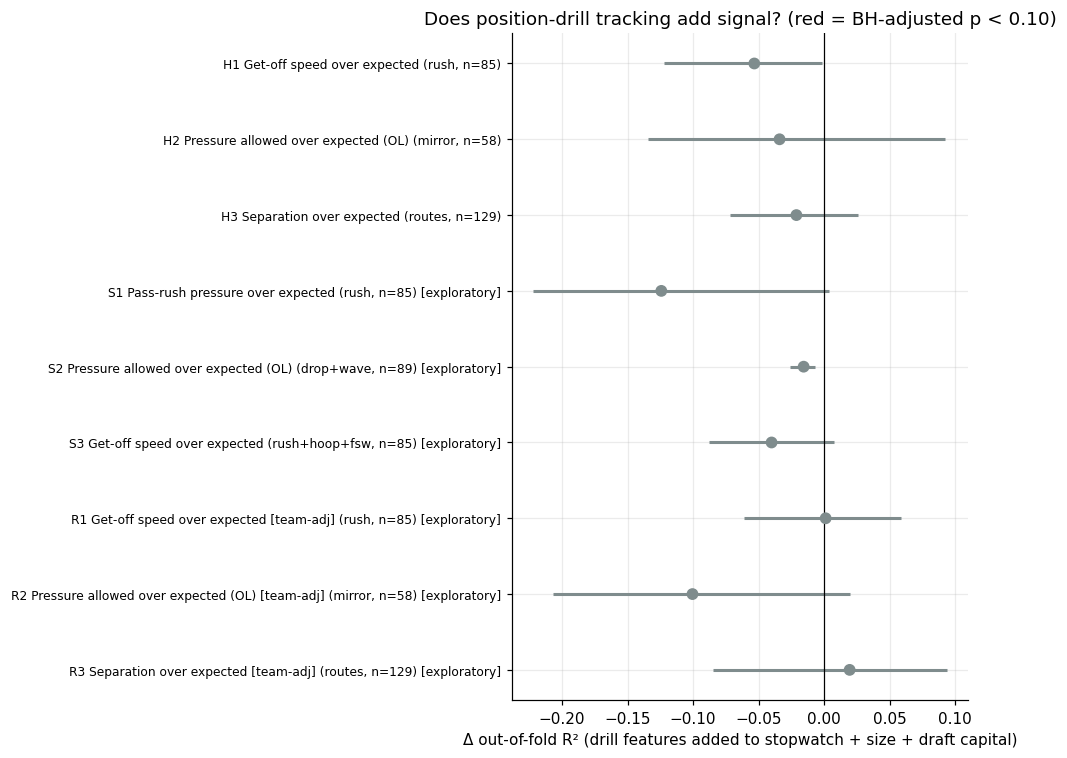

In [7]:
r_ = results.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.6 * len(r_) + 1.6))
cols = ["#c0392b" if p < .1 else "#7f8c8d" for p in r_.p_adj_BH]
ax.hlines(range(len(r_)), r_.lo, r_.hi, color=cols, lw=2); ax.scatter(r_.dR2_CvsB, range(len(r_)), c=cols, s=45, zorder=3)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(range(len(r_)))
ax.set_yticklabels([f"{i} {t} ({d}, n={n})" + ("" if p else " [exploratory]") for i, t, d, n, p in zip(r_.id, r_.target, r_.drills, r_.n, r_.primary)], fontsize=8)
ax.set(xlabel="Δ out-of-fold R² (drill features added to stopwatch + size + draft capital)", title="Does position-drill tracking add signal? (red = BH-adjusted p < 0.10)")
plt.tight_layout(); plt.show()

## 4. Which drill features matter?
Standardised ridge coefficients of drill features (model C) with 95% bootstrap intervals, for each hypothesis. `*` = interval excludes zero. Features are signed so that `a_p02` more negative = harder braking, `cut_decel` likewise.

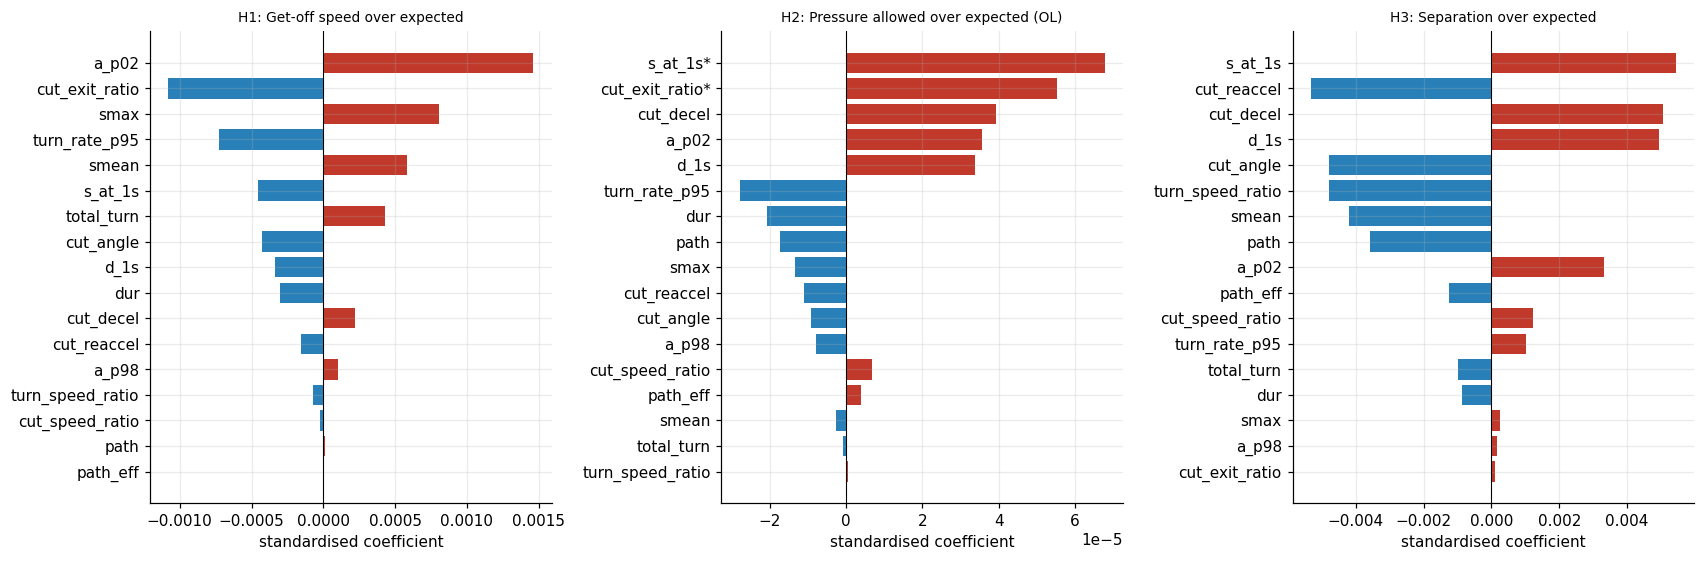

In [8]:
def coefs(S, nboot=300):
    df, cT, y, w = S["df"], S["cT"], S["y"], S["w"]; Xc = df[S["sets"]["C"]]
    full = make_model().fit(Xc, y, ridgecv__sample_weight=w); cc = pd.Series(full[-1].coef_, index=Xc.columns)[cT]
    r, bs = np.random.default_rng(2), []
    for _ in range(nboot):
        i = r.integers(0, len(y), len(y)); m = make_model().fit(Xc.iloc[i], y[i], ridgecv__sample_weight=w[i])
        bs.append(pd.Series(m[-1].coef_, index=Xc.columns)[cT].values)
    lo, hi = np.percentile(bs, 2.5, 0), np.percentile(bs, 97.5, 0)
    return cc, pd.Series((lo > 0) | (hi < 0), index=cT)

prim = [h for h in results[results.primary].id if h in store]
fig, axs = plt.subplots(1, len(prim), figsize=(5.2 * len(prim), 5.2), squeeze=False)
COEF = {}
for ax, h in zip(axs[0], prim):
    cc, sg = coefs(store[h], min(N_BOOT, 300)); COEF[h] = cc
    cc = cc.sort_values(key=np.abs); sg = sg[cc.index]
    ax.barh([c.split("__")[1] + ("*" if sg[c] else "") for c in cc.index], cc.values, color=["#c0392b" if v > 0 else "#2980b9" for v in cc.values])
    ax.axvline(0, color="k", lw=.7); ax.set_title(f"{h}: {store[h]['tname']}", fontsize=9); ax.set_xlabel("standardised coefficient")
plt.tight_layout(); plt.show()

### Temporal holdout: train on 2023–24 draft classes, test on 2025

In [9]:
rows = []
for h, S in store.items():
    df, y, w = S["df"], S["y"], S["w"]; te = (df.draft_year == 2025).values; tr = ~te
    if te.sum() < 12 or tr.sum() < 40: continue
    out = {"id": h, "n_train": int(tr.sum()), "n_test": int(te.sum())}
    for k in ["A", "B", "C"]:
        m = make_model().fit(df.loc[tr, S["sets"][k]], y[tr], ridgecv__sample_weight=w[tr]); out[f"R2_test_{k}"] = r2w(y[te], m.predict(df.loc[te, S["sets"][k]]), w[te])
    out["dR2_test_CvsB"] = out["R2_test_C"] - out["R2_test_B"]; rows.append(out)
holdout = pd.DataFrame(rows); display(holdout.round(3))

,id,n_train,n_test,R2_test_A,R2_test_B,R2_test_C,dR2_test_CvsB
0,H1,59,26,-0.042,0.015,-0.039,-0.054
1,H3,89,40,0.195,0.118,0.093,-0.025
2,S1,59,26,-4.329,-4.406,-3.587,0.819
3,S2,67,22,0.001,0.002,0.004,0.002
4,S3,59,26,-0.042,0.015,-0.009,-0.024
5,R1,59,26,0.116,0.132,0.145,0.014
6,R3,89,40,0.232,0.164,0.204,0.040


## 5. What does a quick pass rusher look like in the drill? (H1)
Speed-vs-time of the pass-rush drill for the top and bottom quartile of NFL get-off speed, plus the paths of the five fastest and five slowest.

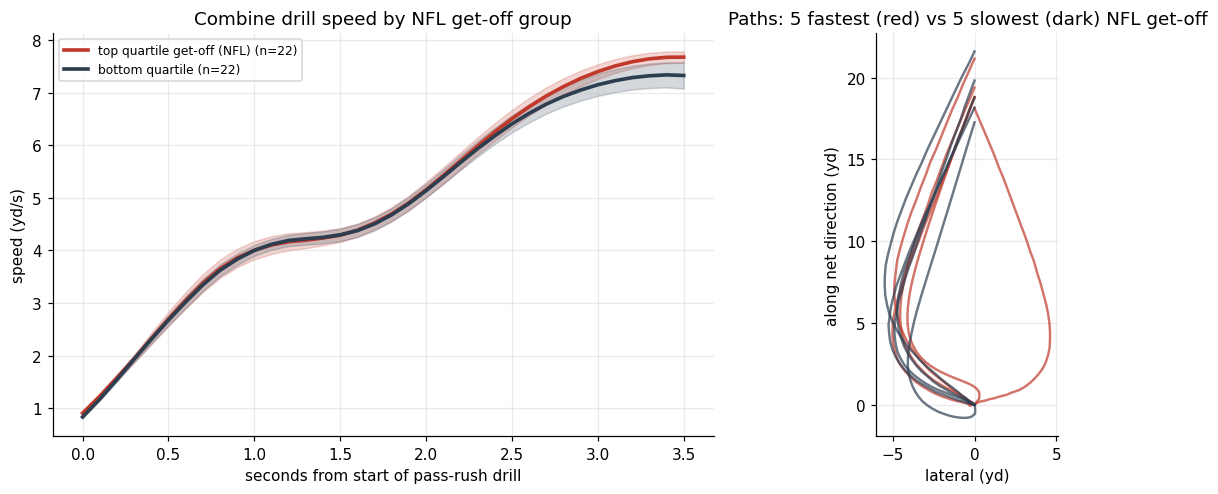

In [10]:
def aligned_speed(ids, name, grid=np.linspace(0, 3.5, 36)):
    d = ctrk[(ctrk.drill_name == name) & ctrk.nfl_id.isin(ids) & (ctrk.entity_type == "PLAYER")]
    curves, paths = {}, {}
    for (nid, eid), g in d.groupby(["nfl_id", "event_id"]):
        if nid in curves: continue
        g = g.sort_values("time"); s = g.s.values; mv = np.where(s > 1.0)[0]
        if len(mv) < 10: continue
        i0 = max(mv[0] - 1, 0); t = _sec(g)[i0:] - _sec(g)[i0]; curves[nid] = np.interp(grid, t, s[i0:], right=np.nan)
        x, y = g.x.values[i0:], g.y.values[i0:]; dx, dy = x - x[0], y - y[0]; ang = np.arctan2(dy[-1], dx[-1]) if len(dx) > 1 else 0
        c, sn = np.cos(np.pi / 2 - ang), np.sin(np.pi / 2 - ang); paths[nid] = (dx * c - dy * sn, dx * sn + dy * c)
    return grid, curves, paths

if "H1" in store:
    S = store["H1"]; df = S["df"]; q1, q3 = df.y.quantile(.25), df.y.quantile(.75)
    top, bot = df[df.y >= q3].nfl_id.values, df[df.y <= q1].nfl_id.values
    grid, cv, pa = aligned_speed(df.nfl_id.values, "PASS_RUSH_DRILL")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for ids, col, lab in [(top, "#c0392b", "top quartile get-off (NFL)"), (bot, "#2c3e50", "bottom quartile")]:
        M = np.array([cv[i] for i in ids if i in cv]); mu, se = np.nanmean(M, 0), np.nanstd(M, 0) / np.sqrt(len(M))
        ax[0].plot(grid, mu, color=col, lw=2.4, label=f"{lab} (n={len(M)})"); ax[0].fill_between(grid, mu - se, mu + se, color=col, alpha=.2)
    ax[0].set(xlabel="seconds from start of pass-rush drill", ylabel="speed (yd/s)", title="Combine drill speed by NFL get-off group"); ax[0].legend(fontsize=8)
    pick = list(df.sort_values("y").nfl_id.values[-5:]) + list(df.sort_values("y").nfl_id.values[:5])
    for i in pick:
        if i in pa: ax[1].plot(*pa[i], color="#c0392b" if i in set(top) else "#2c3e50", alpha=.7, lw=1.6)
    ax[1].set(xlabel="lateral (yd)", ylabel="along net direction (yd)", title="Paths: 5 fastest (red) vs 5 slowest (dark) NFL get-off"); ax[1].set_aspect("equal")
    plt.tight_layout(); plt.show()

### Dose–response for the strongest feature of each primary hypothesis
Quartile means ±1 SE of the shrunk NFL outcome, so a scout can read it without a model.

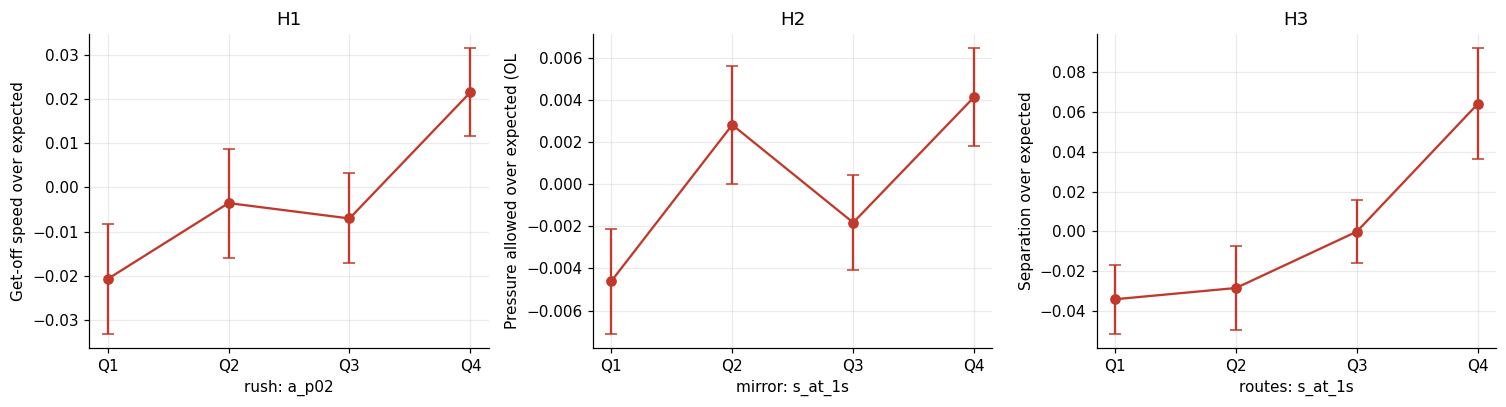

In [11]:
fig, axs = plt.subplots(1, len(prim), figsize=(4.6 * len(prim), 3.8), squeeze=False)
for ax, h in zip(axs[0], prim):
    S = store[h]; df = S["df"]; f1 = COEF[h].abs().sort_values(ascending=False).index[0]
    d = df.dropna(subset=[f1]).copy(); d["q"] = pd.qcut(d[f1], 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
    g = d.groupby("q").apply(lambda x: pd.Series({"m": np.average(x.y, weights=x.w), "se": x.y.std() / np.sqrt(len(x))}))
    ax.errorbar(range(len(g)), g.m, yerr=g.se, fmt="o-", color="#c0392b", capsize=4)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index); ax.set(xlabel=f1.replace("__", ": "), title=f"{h}", ylabel=S["tname"][:34])
plt.tight_layout(); plt.show()

## 6. Practical output: drill-based flags (exploratory)
`drill_lift = prediction(C) − prediction(B)` for the primary hypothesis with the smallest permutation p. Out-of-fold, so no player is scored by a model that saw him. Treat as a *prioritisation list for a film review*, not a forecast.

In [12]:
if len(results):
    lead = results[results.primary].sort_values("p_perm").iloc[0].id; S = store[lead]; df = S["df"].copy()
    df["pred_B"], df["pred_C"] = S["P"]["B"], S["P"]["C"]; df["drill_lift"] = df.pred_C - df.pred_B
    show = ["display_name", "nfl_position", "draft_year", "draft_overall_pick", "n", "y", "pred_B", "pred_C", "drill_lift"]
    print("Lead hypothesis:", lead, S["tname"])
    display(df.nlargest(6, "drill_lift")[show].round(3)); display(df.nsmallest(6, "drill_lift")[show].round(3))
    df.to_csv("drill_lift_lead.csv", index=False)
results.to_csv("results_v2_nested_models.csv", index=False); dw.to_csv("drill_features_by_player.csv", index=False)
focused.to_csv("focused_tests.csv", index=False); rel_drill.to_csv("drill_feature_reliability.csv")

Lead hypothesis: H2 Pressure allowed over expected (OL)


,display_name,nfl_position,draft_year,draft_overall_pick,n,y,pred_B,pred_C,drill_lift
45,Anthony Belton,T,2025,54.0,351,0.010,-0.005,-0.001,0.004
51,Jalen Travis,T,2025,127.0,257,0.001,-0.004,-0.001,0.003
27,Jarrett Kingston,T,2024,215.0,152,-0.010,-0.000,0.003,0.003
50,Caleb Rogers,G,2025,98.0,240,-0.003,-0.002,0.001,0.003
47,Tate Ratledge,G,2025,57.0,631,-0.017,-0.001,0.001,0.002
1,J.C. Latham,T,2024,7.0,1128,0.007,-0.003,-0.001,0.002


,display_name,nfl_position,draft_year,draft_overall_pick,n,y,pred_B,pred_C,drill_lift
36,Will Campbell,T,2025,4.0,611,0.023,-0.006,-0.009,-0.003
39,Tyler Booker,G,2025,12.0,588,-0.010,0.005,0.003,-0.002
19,Sedrick Van Pran-Granger,C,2024,141.0,111,-0.008,0.003,0.001,-0.002
10,Kingsley Suamataia,G,2024,63.0,837,-0.006,0.002,0.000,-0.002
48,Dylan Fairchild,G,2025,81.0,616,-0.014,0.002,0.000,-0.002
32,Javion Cohen,G,2024,NaN,161,0.002,0.004,0.002,-0.002


## 7. Limitations
* **Small N**: ~60–110 players per hypothesis; ridge + repeated CV + permutation tests + BH correction, but intervals are wide.
* **Rookies only**; no opponent/teammate quality; only players with enough snaps are scored.
* **Drill tracks have no ball/partner reference**, so mirror and route features describe the athlete's own movement, not whether he "won" the rep.
* **Features are generic** (speed, acceleration, turning, break) and not hand-tuned per drill; position coaches may want drill-specific events.
* **Six hypotheses** were pre-specified; the three primary ones carry the headline claim. Exploratory ones are labelled.